Homework 5, problem 3, part d

In [1]:
# libraries and parameters

import numpy as np
import matplotlib.pyplot as plt

dx = 0.02
L = 30.0
x = np.arange(-L/2, L/2, dx)
N = len(x)
kappa = 0.3
dt = 0.05
t_max = 40.0
time_steps = int(t_max / dt)

# from part a
a_minus = 0.2031 # narrow bump 
a_plus = 1.6941 # wide bump

In [2]:
# w(x) = 2*e^-|x| - e^-|x|/2
w = 2.0 * np.exp(-np.abs(x)) - np.exp(-np.abs(x) / 2.0)
w_fft = np.fft.fft(np.fft.fftshift(w)) * dx

def primitive_W(z):
    """Analytical primitive integral W(z) = integral_0^z w(s)ds used for initialization."""
    return np.sign(z) * (2.0 * np.exp(-np.abs(z) / 2.0) - 2.0 * np.exp(-np.abs(z)))

def generate_initial_profile(a_width):
    """Generates an initial steady-state profile configuration U(x) with half-width a_width."""
    return primitive_W(x + a_width) - primitive_W(x - a_width)

In [3]:
def run_neural_field(initial_a):
    """Simulates the field evolution using Forward Euler & FFT Convolution."""
    U = generate_initial_profile(initial_a)
    
    # for temporal shapes
    history = [U.copy()]
    save_intervals = np.linspace(0, time_steps - 1, 6, dtype=int)
    
    for step in range(time_steps):
        H = np.where(U >= kappa, 1.0, 0.0) # H(U - kappa)
        
        spatial_input = np.fft.ifft(np.fft.fft(H) * w_fft).real
        
        U = U + dt * (-U + spatial_input)
        
        if step in save_intervals:
            history.append(U.copy())
            
    return history

In [4]:
# perturbation cases
# half-width is below narrow threshold (extinction)
history_shrink = run_neural_field(a_minus * 0.90)

# half-width is above narrow threshold (stabilization to a_+)
history_grow = run_neural_field(a_minus * 1.30)

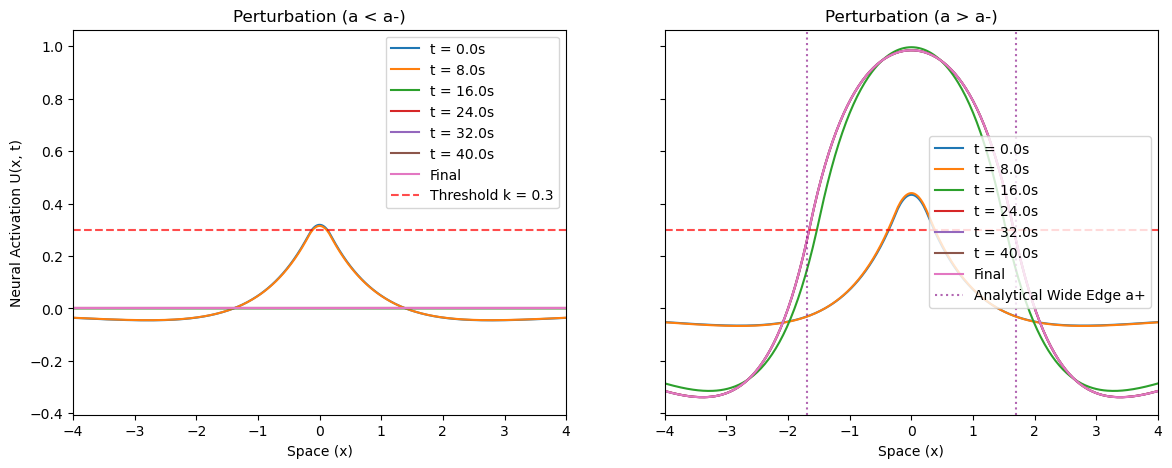

In [7]:
# plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# shrinking bump
ax1 = axes[0]
for idx, U_t in enumerate(history_shrink):
    ax1.plot(x, U_t, label=f't = {idx * (t_max/5):.1f}s' if idx < 6 else 'Final')
ax1.axhline(kappa, color='red', linestyle='--', alpha=0.7, label=r'Threshold k = 0.3')
ax1.set_xlim(-4, 4)
ax1.set_title('Perturbation (a < a-)')
ax1.set_xlabel('Space (x)')
ax1.set_ylabel('Neural Activation U(x, t)')
ax1.legend()

# growing bump
ax2 = axes[1]
for idx, U_t in enumerate(history_grow):
    ax2.plot(x, U_t, label=f't = {idx * (t_max/5):.1f}s' if idx < 6 else 'Final')
ax2.axhline(kappa, color='red', linestyle='--', alpha=0.7)
ax2.axvline(a_plus, color='purple', linestyle=':', alpha=0.6, label=r'Analytical Wide Edge a+')
ax2.axvline(-a_plus, color='purple', linestyle=':', alpha=0.6)
ax2.set_xlim(-4, 4)
ax2.set_title('Perturbation (a > a-)')
ax2.set_xlabel('Space (x)')
ax2.legend()

plt.show()